# Project 2: Image Classification
## Notebook 1 — Dataset Construction
The supplied starter's sections 1–6 are retained and extended; `ddgs_scraper.py` remains beside this notebook.

**Recorded acquisition evidence from the uploaded notebook:** 400 downloads for each of claw-hammer, ball-peen-hammer and sledgehammer; 1,200 manifest records; zero unreadable/missing files reported by its integrity pass.

# Note:

Code source is from instructor GitHub and modified for the purpose of the project execution

# Building an Image Dataset by Scraping

Every image dataset i have trained on so far arrived clean.

This notebook is were I started point for P2 Notebook 1. It demonstrates the provided scraper on
a small example. My tasks is to replace my own classes, scrape at full scale,
and justification. The download-integrity check, the accounting table, and the manifest are
built in run them.

## My Learning Objectives

- Choose image classes that make a learnable, non-trivial classification problem
- Write several search queries per class and explain why one query is not enough
- Run a scraper with arguments you can justify, rather than defaults you inherited
- Account for the gap between images requested, images downloaded, and images readable
- Export a manifest that records what you actually trained on

## This notebook covers

1. What the scraper does
2. Declaring your classes and queries
3. Running the scraper
4. Accounting for what came back
5. A first look at the images
6. Turning the records into a manifest

**Dataset:** "images". Built via the `ddgs` package.

## 0. Setup
Read `ddgs_scraper.py` before using it. The supplied helper is copied without modification.
Images stay outside Git, at my configured Windows class data path. `P2_DATA_ROOT` I override that path.
So, I set `classes_confirmed=true` only after checking my real classes and queries.

In [11]:
from pathlib import Path
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

# Locate project modules.
REPO_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == 'notebooks'
    else Path.cwd()
)
sys.path.insert(0, str(REPO_ROOT / 'notebooks'))
sys.path.insert(0, str(REPO_ROOT / 'app'))

from pipeline_utils import (
    ROOT, load_config, save_json, digest, checked_manifest,
    as_bool, resize_rgb, pixel_hash, dhash, prepared_inputs
)

# Explicit location of your existing dataset.
# Change this only if you moved the Images folder.
os.environ['P2_DATA_ROOT'] = (
    r'C:\Users\lawra\Fall 2026-2027 Semester Document'
    r'\MSDS 565-01\Project 2 Image Classification\Images'
)

config, DATA_ROOT = load_config(require_confirmation=False)
DATA_ROOT = Path(DATA_ROOT)

RAW = DATA_ROOT / 'raw'
PREPARED = DATA_ROOT / 'prepared'

assert config['seed'] == 42, (
    'This assignment requires random_state=42.'
)
assert config['resize_strategy'] == 'pad'

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
pd.set_option('display.max_rows', 25)

print('Project 2: Image Classification')
print('Dataset root:', DATA_ROOT)
print('Scraped images:', RAW)
print('Prepared arrays:', PREPARED)

# Check the existing dataset rather than creating an empty raw folder.
if not RAW.is_dir():
    raise FileNotFoundError(
        f'Dataset folder not found: {RAW}\n'
        'Update P2_DATA_ROOT to your actual Images folder.'
    )

labels = [
    'claw-hammer',
    'ball-peen-hammer',
    'sledgehammer'
]

for label in labels:
    class_folder = RAW / label

    if not class_folder.is_dir():
        raise FileNotFoundError(
            f'Missing class folder: {class_folder}'
        )

    file_count = sum(
        path.is_file() for path in class_folder.iterdir()
    )
    print(f'{label}: {file_count} files — {class_folder}')

print(
    '\nThese are file counts only. Section 4 checks readability; '
    'Notebook 2 checks labels and duplicates.'
)

import ddgs_scraper
print('Supplied scraper:', Path(ddgs_scraper.__file__).name)

Project 2: Image Classification
Dataset root: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images
Scraped images: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
Prepared arrays: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\prepared
claw-hammer: 400 files — C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw\claw-hammer
ball-peen-hammer: 400 files — C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw\ball-peen-hammer
sledgehammer: 400 files — C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw\sledgehammer

These are file counts only. Section 4 checks readability; Notebook 2 checks labels and duplicates.
Supplied scraper: ddgs_scraper.py


## 1. What the Scraper Does

`ddgs_scraper.py` wraps the `ddgs` package, which queries web image search. By default it asks Bing
Images directly the same index DuckDuckGo Images draws its results from because that is the
backend that works reliably (see `backend` in section 3). The pieces you will actually call are:

| Function | What it does |
|---|---|
| `search_images(query, ...)` | One search, paged until it has enough results. Returns raw result records — image URL, page URL, title, reported size |
| `download_image(url, ...)` | Fetches one URL and returns an RGB PIL image, or `None` if it isn't one |
| `passes_image_filters(img, ...)` | Checks a downloaded image against size and aspect-ratio limits |
| `scrape_class(label, queries, ...)` | All queries for one class, into one folder |
| `build_image_dataset(class_queries, ...)` | Every class. **This is the one call.** |

Two things the scraper deliberately does *not* do, because they are your job in Notebook 2:
it does not check for duplicate images, and it does not judge whether the picture is actually of
the thing you searched for.

Read the module before running it. The arguments below are not magic numbers and you will be asked
to defend them.

In [12]:
# Display the supplied source so its filters, retries and returned fields can be reviewed.
import inspect
print(inspect.getsource(ddgs_scraper.build_image_dataset))

def build_image_dataset(
    class_queries: dict,
    save_dir: str | Path,
    images_per_class: int = 250,
    results_per_query: int = 200,
    aspect_ratio_range: tuple = (0.5, 2.0),
    min_resolution: tuple = (200, 200),
    per_image_timeout: int = 10,
    backend: str = "bing",
    safesearch: str = "moderate",
    region: str = "us-en",
    require_query_match: bool = True,
    query_delay: tuple = (2.0, 5.0),
    continue_on_error: bool = True,
    verbose: bool = True,
) -> tuple[list[dict], dict]:
    """
    Download a labeled image dataset from an image search engine.

    One folder per class is created inside save_dir. Every class may have
    several search queries, and results from all of a class's queries land in
    the same folder — using several queries per class is how you get a class
    that looks like the whole category instead of one narrow slice of it.
    Every query is used: downloads take turns between a class's queries, so
    each supplies a roughly equ

In [13]:
# Read the actual argument documentation, not assumed package defaults.
help(ddgs_scraper.build_image_dataset)

Help on function build_image_dataset in module ddgs_scraper:

build_image_dataset(class_queries: dict, save_dir: str | pathlib.Path, images_per_class: int = 250, results_per_query: int = 200, aspect_ratio_range: tuple = (0.5, 2.0), min_resolution: tuple = (200, 200), per_image_timeout: int = 10, backend: str = 'bing', safesearch: str = 'moderate', region: str = 'us-en', require_query_match: bool = True, query_delay: tuple = (2.0, 5.0), continue_on_error: bool = True, verbose: bool = True) -> tuple[list[dict], dict]
    Download a labeled image dataset from an image search engine.

    One folder per class is created inside save_dir. Every class may have
    several search queries, and results from all of a class's queries land in
    the same folder — using several queries per class is how you get a class
    that looks like the whole category instead of one narrow slice of it.
    Every query is used: downloads take turns between a class's queries, so
    each supplies a roughly equal

### 2.3 Declare and Defend the Class Plan

**Task:** Construct a custom dataset of claw hammers, ball-peen hammers,
and sledgehammers.

**Decision:** I used three related hand-tool classes. All share a handle
and striking head, so classification requires distinguishing tool features.

| Class | Distinguishing features | Expected difficulties |
|---|---|---|
| Claw hammer | Split claw opposite the striking face. | Viewing angle may hide the claw; handles and backgrounds overlap with other classes. |
| Ball-peen hammer | Rounded peen opposite a flat striking face. | Cropping or oblique views may hide the rounded end. |
| Sledgehammer | Broad, heavy, usually double-faced head; often a longer handle. | Cropping removes size cues; short-handled models can resemble other hammers. |

**Steps and explanation:**

1. Declare three classes, satisfying the required range of 3–10.
2. Use three queries per class to vary wording, materials, and settings.
3. Target 400 readable acquisitions per class as a cleaning buffer.
4. Require Notebook 2 to verify at least 200 usable, unique, correctly
   labeled images per class after cleaning.
5. Record a confusion prediction before modeling.

**Expected outcome:** A custom web-acquired dataset whose classes share
visual structure but differ in head geometry.

**Prediction before modeling:** Claw hammer and ball-peen hammer will be
the most frequently confused pair because their distinguishing rear
heads may be obscured. Notebook 3 will compare this prediction with
the observed confusion matrix.

**Interpretation:** This is a pre-model hypothesis, not an experimental
result. Readability and acquisition counts do not establish label
correctness or uniqueness.

In [14]:
CLASS_QUERIES = {
    'claw-hammer': [
        'claw hammer tool photograph',
        'claw hammer workshop',
        'claw hammer wooden handle'
    ],
    'ball-peen-hammer': [
        'ball peen hammer tool photograph',
        'ball pein hammer workshop',
        'ball peen hammer wooden handle'
    ],
    'sledgehammer': [
        'sledgehammer tool photograph',
        'sledge hammer workshop',
        'sledgehammer wooden handle'
    ]
}

PREDICTED_CONFUSION_PAIR = ['claw-hammer', 'ball-peen-hammer']
CONFUSION_REASON = (
    'Both classes have similar handles and proportions. '
    'An oblique or cropped view can hide the distinguishing '
    'claw or rounded peen.'
)

assert 3 <= len(CLASS_QUERIES) <= 10
assert all(len(queries) >= 2 for queries in CLASS_QUERIES.values())
assert len(PREDICTED_CONFUSION_PAIR) == 2
assert set(PREDICTED_CONFUSION_PAIR).issubset(CLASS_QUERIES)

config.update({
    'class_queries': CLASS_QUERIES,
    'confusion_prediction': PREDICTED_CONFUSION_PAIR,
    'confusion_reason': CONFUSION_REASON,
    'classes_confirmed': True,
    'class_plan_status': 'Declared three-class hammer dataset',
    'images_per_class': 400,
    'results_per_query': 300,
    'min_resolution': [224, 224],
    'aspect_ratio_range': [0.5, 2.0],
    'per_image_timeout': 10,
    'backend': 'bing',
    'safesearch': 'moderate',
    'region': 'us-en',
    'require_query_match': True,
    'query_delay': [2.0, 5.0]
})

(ROOT / 'config').mkdir(parents=True, exist_ok=True)
save_json(ROOT / 'config/project.json', config)

display(pd.DataFrame(
    [(label, query)
     for label, queries in CLASS_QUERIES.items()
     for query in queries],
    columns=['label', 'exact_query']
))

print('Prediction before modeling:', PREDICTED_CONFUSION_PAIR)
print('Reason:', CONFUSION_REASON)

,label,exact_query
0,claw-hammer,claw hammer tool photograph
1,claw-hammer,claw hammer workshop
2,claw-hammer,claw hammer wooden handle
3,ball-peen-hammer,ball peen hammer tool photograph
4,ball-peen-hammer,ball pein hammer workshop
5,ball-peen-hammer,ball peen hammer wooden handle
6,sledgehammer,sledgehammer tool photograph
7,sledgehammer,sledge hammer workshop
8,sledgehammer,sledgehammer wooden handle


Prediction before modeling: ['claw-hammer', 'ball-peen-hammer']
Reason: Both classes have similar handles and proportions. An oblique or cropped view can hide the distinguishing claw or rounded peen.


**Outcome:** I declared **three hammer classes with three search queries each**, totaling **nine queries**. The queries vary wording, setting, and handle material to encourage a broader range of images. Alternative spellings, including “peen/pein” and “sledgehammer/sledge hammer,” expand search coverage.

Before modeling, I predicted that **claw-hammer and ball-peen-hammer** would be the most frequently confused pair. Their handles and proportions overlap, while cropping or viewing angle can hide the distinguishing claw or rounded peen.

**Interpretation:** Multiple queries encourage variation but do not guarantee diverse or correctly labeled results. The predicted confusion pair remains a hypothesis to evaluate against Notebook 3’s confusion matrix.

**Execution status:** I'm not claiming any dataset result until this cell runs successfully on the actual data.

## 3. Running the Scraper

I selected three hammer classes: **claw-hammer, ball-peen-hammer, and sledgehammer**. I configured three search queries per class and requested **400 downloads per class**, providing a buffer above the assignment’s requirement of 200 usable images per class after cleaning.

| Argument              | Setting                                                   | Justification                                                                                                                            |
| --------------------- | --------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------- |
| `save_dir`            | Unique batch folders under the external dataset directory | Prevents filename collisions during additional collection. Images are then moved into `Images/raw/<label>`, outside the repository.      |
| `images_per_class`    | 400                                                       | Allows for removing incorrectly labeled, duplicate, or unreadable images while working toward at least 200 usable images per class.      |
| `results_per_query`   | 300                                                       | Provides candidate results to accommodate failed downloads and rejected images. This setting does not guarantee 300 downloads per query. |
| `min_resolution`      | 224 × 224                                                 | Rejects small thumbnails that would require enlargement to the intended model-input dimensions.                                          |
| `aspect_ratio_range`  | 0.5–2.0                                                   | Filters extreme image shapes, including many banners. However, it may also exclude legitimate photographs of long tools.                 |
| `per_image_timeout`   | 10 seconds                                                | Limits the time spent waiting for an individual download from an unavailable or slow host.                                               |
| `backend`             | `bing`                                                    | Uses the backend recommended by the supplied scraper documentation.                                                                      |
| `safesearch`          | `moderate`                                                | Requests moderate filtering. The supplied documentation states that Bing applies its own default rather than honoring this argument.     |
| `region`              | `us-en`                                                   | Records the intended search region. The supplied documentation states that Bing ignores this parameter.                                  |
| `require_query_match` | `True`                                                    | Rejects obviously unrelated search results while leaving semantic label verification to manual review.                                   |
| `query_delay`         | 2–5 seconds                                               | Spaces search requests to reduce request bursts.                                                                                         |

The recorded acquisition outputs showed **400 downloads per class, totaling 1,200 manifest records**, with **zero unreadable or missing files reported by the integrity check**. The displayed rerun reused those records and reported **zero new records**. These are recorded results from the uploaded notebook, rather than a newly verified scrape.

### 3.1 Handling Rate Limits

I configured collection by class so that additional acquisition can target only the classes that need more images. Unique batch folders prevent new downloads from overwriting existing filenames.

An empty result can indicate throttling, an unsuccessful query, or another retrieval problem. If this occurs, I will review the output and retry the affected class after waiting. The recorded counts alone do not establish whether throttling occurred during acquisition.

### 3.2 Checking Search Relevance

I enabled `require_query_match` to reduce unrelated results. However, matching words in a title or URL does not prove that an image belongs to the correct hammer class.

I use Section 5 for an initial visual inspection. Notebook 2 performs manual label review and duplicate removal, then determines whether each class retains at least **200 usable images**. The acquisition and readability counts do not establish that requirement by themselves.


### 3.3 Scraper argument decisions

**Task:** Collect varied source images while preserving provenance.

**Decision:** Target 400 readable acquisitions per class using three
queries per class. Request only the remaining deficit during top-ups.

| Argument | Setting | Justification |
|---|---|---|
| class_queries | Three classes; three queries each | Varies wording, materials, and settings. |
| save_dir | Unique batch folder outside the repository | Keeps images outside Git and prevents filename collisions. |
| images_per_class | 400 initially; remaining deficit for top-ups | Provides a cleaning buffer above the required 200 usable images. |
| results_per_query | 300 | Allows for unavailable hosts, overlapping results, and quality filtering. |
| min_resolution | 224 × 224 | Rejects small thumbnails before model-input preparation. |
| aspect_ratio_range | 0.5–2.0 | Excludes extreme banners; may also exclude legitimate long-tool photographs. |
| per_image_timeout | 10 seconds | Limits time spent on slow image hosts. |
| backend | bing | Uses the backend selected by the supplied helper. |
| safesearch | moderate | Records the requested setting; consult the supplied helper for backend behavior. |
| region | us-en | Records the intended region; consult the supplied helper for backend behavior. |
| require_query_match | True | Filters obviously unrelated results; does not verify labels. |
| query_delay | 2–5 seconds | Reduces request bursts without guaranteeing avoidance of throttling. |
| continue_on_error | True | Preserves progress when a class fails; accounting must still show the shortfall. |
| verbose | False | Keeps output manageable while retaining class-level progress. |

**Steps:** Collect images, preserve actual source URLs and queries,
decode saved files, calculate counts, and attempt top-ups for short classes.

**Outcome:** The following cells report actual acquisition counts.
Historical uploaded outputs are not evidence of a new scrape.

**Interpretation:** Readability establishes file integrity only.
Notebook 2 verifies labels, duplicates, and the post-cleaning minimum.

**Existing data:** Import the real source manifest from
`DATA_ROOT/P2_source_manifest.csv` when needed. Preserve existing
manifest columns, including Notebook 2's `kept` decisions.

**Reruns:** Explicit extra collection can be requested with
`P2_RESCRAPE_CLASSES`. Automatic top-ups are skipped after cleaning
decisions have been recorded.

In [5]:
import os, uuid, shutil

# Keep scraped images separate from the existing demo images.
RAW = DATA_ROOT / 'raw'
RAW.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = ROOT / 'data/P2_manifest.csv'
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
SOURCE = DATA_ROOT / 'P2_source_manifest.csv'

# Load existing source records, or initialize an empty manifest.
required = ['filename', 'label', 'source_url', 'query', 'readable']
existing = (
    pd.read_csv(MANIFEST_PATH, keep_default_na=False)
    if MANIFEST_PATH.exists()
    else pd.DataFrame(columns=required)
)

assert set(required).issubset(existing.columns), 'Manifest schema is incomplete.'
if not existing.empty:
    checked_manifest(config)  # Reject unsafe paths or mismatched labels before touching files.

if existing.empty and SOURCE.exists():
    # Import actual source information for an existing scraped dataset.
    existing = pd.read_csv(SOURCE, keep_default_na=False)
    assert set(required).issubset(existing.columns), (
        'Existing dataset needs its real source manifest.'
    )
    assert set(existing['label']) == set(CLASS_QUERIES), (
        'Source manifest labels do not match CLASS_QUERIES.'
    )
    existing.to_csv(MANIFEST_PATH, index=False)

if existing.empty and any(RAW.rglob('*.*')):
    raise ValueError(
        f'Unmanifested files found in {RAW}. '
        'Supply their actual source manifest before proceeding.'
    )

rescrape = [
    label.strip()
    for label in os.environ.get('P2_RESCRAPE_CLASSES', '').split(',')
    if label.strip()
]
assert set(rescrape).issubset(CLASS_QUERIES), (
    'Requested rescrape classes must exist in CLASS_QUERIES.'
)

missing = [
    label for label in CLASS_QUERIES
    if label not in set(existing['label'])
]
# Include classes already below the 300-readable acquisition buffer.
requested_labels = list(dict.fromkeys(missing + rescrape))

new_records = []
batch_summary = {}

for label in requested_labels:
    # Unique batch folders prevent downloaded filenames from colliding.
    batch_id = uuid.uuid4().hex[:12]
    batch_dir = DATA_ROOT / 'scrape_batches' / batch_id

    print(f'Collecting images for: {label}', flush=True)

    records, summary = ddgs_scraper.build_image_dataset(
        class_queries={label: CLASS_QUERIES[label]},
        save_dir=batch_dir,
        images_per_class=config['images_per_class'],
        results_per_query=config['results_per_query'],
        aspect_ratio_range=tuple(config['aspect_ratio_range']),
        min_resolution=tuple(config['min_resolution']),
        per_image_timeout=config['per_image_timeout'],
        backend=config['backend'],
        safesearch=config['safesearch'],
        region=config['region'],
        require_query_match=config['require_query_match'],
        query_delay=tuple(config['query_delay']),
        continue_on_error=True,
        verbose=False
    )

    batch_summary[label] = summary['classes'][label]
    class_dir = RAW / label
    class_dir.mkdir(parents=True, exist_ok=True)

    for record in records:
        row = dict(record)
        source = batch_dir / label / row['filename']
        row['filename'] = batch_id + '_' + row['filename']

        shutil.move(str(source), str(class_dir / row['filename']))
        row['readable'] = True  # Verified again in the later integrity pass.
        new_records.append(row)

    # Save progress after each class.
    accumulated = pd.concat(
        [existing, pd.DataFrame(new_records)],
        ignore_index=True
    )
    accumulated.to_csv(MANIFEST_PATH, index=False)
    print(label, batch_summary[label])

manifest = pd.concat(
    [existing, pd.DataFrame(new_records)],
    ignore_index=True
)

if manifest.empty:
    raise RuntimeError(
        'No images downloaded. Check the network, search queries, '
        'or rate limiting before retrying.'
    )

assert not manifest.duplicated(['label', 'filename']).any(), (
    'Duplicate label/filename records found.'
)

manifest.to_csv(MANIFEST_PATH, index=False)

save_json(ROOT / 'data/P2_dataset_contract.json', {
    'data_root': str(DATA_ROOT), 'raw_subdirectory': 'raw',
    'class_queries': CLASS_QUERIES, 'config': config})
print('Image directory:', RAW)
print('New records:', len(new_records), '| Total records:', len(manifest))

Image directory: C:\Users\lawra\Fall 2026-2027 Semester Document\MSDS 565-01\Project 2 Image Classification\Images\raw
New records: 0 | Total records: 1200


#### Outcome / output
The uploaded run recorded 400 downloads per class, or 1,200 records. Rerunning this cell reads existing records and requests missing/short classes; `P2_RESCRAPE_CLASSES` requests additional named classes.
#### Interpretation
400 downloads provide a 200-image removal allowance per class before falling below the floor. They do not guarantee that 200 survive semantic and duplicate review. Empty or low-yield results can reflect throttling; wait and retry only affected classes. Unique batch names prevent filename collisions, not content duplicates.

## 4. Accounting for What Came Back

I tracked each class from **requested** through **downloaded** to **readable** to account for differences between the acquisition target and the files available for cleaning.

Section 4.1 checks whether each manifest-listed image can be fully decoded. Section 4.2 summarizes the counts by class and flags classes with fewer than 300 readable images, indicating a reduced cleaning buffer.

The recorded acquisition outputs showed **400 downloads per class, totaling 1,200 manifest records**, with **zero unreadable or missing files reported**. These historical results must be verified against the local files when the notebook is rerun.

### 4.1 Download Integrity

Downloaded files can be empty, truncated, or invalid despite having an image extension. Although the scraper decodes images before saving them, I included a separate integrity check to verify the saved files.

The check opens each image with PIL inside a `try`/`except` block and calls `image.load()` to decode its pixels. `Image.open()` alone is insufficient because it generally identifies the image without fully decoding its contents.

Files that fail this check are recorded as unreadable, and existing invalid files are deleted. Files already removed through recorded Notebook 2 cleaning decisions are handled separately to preserve the cleaning history.

**Interpretation:** A readable image is not necessarily correctly labeled or unique. Notebook 2 performs those checks and verifies the minimum of 200 usable images per class after cleaning.

In [6]:
def cleaning_decisions_present():
    """Detect recorded Notebook 2 keep/remove decisions."""
    if 'kept' not in manifest.columns:
        return False

    values = manifest['kept'].astype(str).str.strip().str.lower()
    return values.isin({'true', 'false', '1', '0'}).any()


def inspect_acquired_files():
    """Decode acquired files while preserving recorded cleaning history."""
    flags = []
    failures = []

    for row in manifest.itertuples(index=False):
        path = RAW / row.label / row.filename
        kept_value = str(getattr(row, 'kept', '')).strip().lower()
        deliberately_removed = kept_value in {'false', '0'}

        # A deliberately removed file is not a new acquisition failure.
        if deliberately_removed and not path.exists():
            flags.append(
                str(row.readable).strip().lower() in {'true', '1'}
            )
            continue

        try:
            with Image.open(path) as image:
                image.load()
            flags.append(True)
        except (OSError, ValueError) as error:
            flags.append(False)
            failures.append({
                'label': row.label,
                'filename': row.filename,
                'error': str(error)
            })
            if path.is_file():
                path.unlink()

    manifest['readable'] = pd.Series(
        flags, index=manifest.index, dtype=bool
    )
    manifest.to_csv(MANIFEST_PATH, index=False)
    return failures


def current_file_counts():
    """Count manifest-listed readable files actually present on disk."""
    counts = {}

    for label in CLASS_QUERIES:
        part = manifest[
            manifest['label'].eq(label)
            & as_bool(manifest['readable'])
        ]
        counts[label] = sum(
            (RAW / label / filename).is_file()
            for filename in part['filename']
        )

    return pd.Series(counts, name='readable_present', dtype='int64')


manifest['readable'] = as_bool(manifest['readable'])
unreadable = inspect_acquired_files()

print('Unreadable or unexpectedly missing files:', len(unreadable))
display(pd.DataFrame(
    unreadable, columns=['label', 'filename', 'error']
).head(10))

Unreadable or unexpectedly missing files: 0


,label,filename,error


### 4.2 Raw Accounting

I summarized acquisition results in one row per class, distinguishing new downloads from existing manifest records:

* **Requested new:** The number requested for each class during the current run.
* **Downloaded new:** The number saved during the current run.
* **Manifest records total:** All acquisition records accumulated across runs.
* **Unreadable total:** Records marked unreadable, including invalid or unexpectedly missing files.
* **Readable total:** Records marked readable following the integrity check.

A class is flagged **at risk** when it has fewer than **300 readable images**. This threshold provides a cleaning buffer above the required **200 usable images per class**; it does not guarantee that enough correctly labeled, unique images will remain.

The recorded acquisition results showed **400 readable images per class**, so no class fell below the 300-image threshold. The displayed rerun reused the existing **1,200 records** and added **zero new images**.

Any class below the threshold should be reviewed for additional collection before manual cleaning. Section 4.3 checks actual file availability against the 400-image acquisition target, while Notebook 2 verifies the final post-cleaning minimum.

In [7]:
rows = []
for label in CLASS_QUERIES:
    part = manifest[manifest.label.eq(label)]
    readable = int(part.readable.sum())
    rows.append({'class': label, 'queries': len(CLASS_QUERIES[label]),
                 'requested_new': config['images_per_class'] if label in requested_labels else 0,
                 'downloaded_new': sum(r['label'] == label for r in new_records),
                 'manifest_records_total': len(part), 'unreadable_total': len(part) - readable,
                 'readable_total': readable, 'at_risk_under_300': readable < 300})
counts = pd.DataFrame(rows)
display(counts)
counts.to_csv(ROOT / 'data/P2_scrape_accounting.csv', index=False)
for row in counts.itertuples():
    display(Markdown(f"**{row[1]}:** {row.readable_total} readable of {row.manifest_records_total} acquired records. "
                     + ("Below the 300-image buffer: collect more before cleaning." if row.at_risk_under_300
                        else "Acquisition buffer reached; manual cleaning still determines usability.")))

,class,queries,requested_new,downloaded_new,manifest_records_total,unreadable_total,readable_total,at_risk_under_300
0,claw-hammer,3,0,0,400,0,400,False
1,ball-peen-hammer,3,0,0,400,0,400,False
2,sledgehammer,3,0,0,400,0,400,False


**claw-hammer:** 400 readable of 400 acquired records. Acquisition buffer reached; manual cleaning still determines usability.

**ball-peen-hammer:** 400 readable of 400 acquired records. Acquisition buffer reached; manual cleaning still determines usability.

**sledgehammer:** 400 readable of 400 acquired records. Acquisition buffer reached; manual cleaning still determines usability.

### 4.3 Full-Scale Collection and Top-Ups

**Task:** Verify actual file availability and collect additional images when a class has fewer than 400 readable files before manual cleaning.

**Decision:** Allow up to two top-up rounds, requesting only each class’s remaining deficit. Use unique batch filenames to prevent overwriting existing files and reject repeated image URLs when the helper provides an `image_url` field.

**Steps:**

1. Recheck image readability and count manifest-listed files present on disk.
2. Calculate each class’s shortfall against the 400-image target.
3. Request additional images for classes below the target.
4. Save new records with their actual source information.
5. Recheck files and report any remaining shortfalls.

**Outcome:** The cell reports current file counts and top-up attempts. If all classes already have 400 readable files, no additional collection is needed. If the target remains unmet after the permitted rounds, the cell raises an error for review. The recorded acquisition counts suggest no top-up would be needed, but local file availability must be verified on rerun.

**Interpretation:** Unique filenames and different URLs do not establish image uniqueness. Notebook 2 must verify correct labels, remove duplicates, and confirm at least 200 usable images per class. Automatic top-ups are skipped when cleaning decisions already exist to avoid replenishing intentionally removed images.

In [8]:
import uuid
import shutil

TARGET_READABLE = 400
MAX_TOPUP_ROUNDS = 2

TOPUP_COLUMNS = [
    'round', 'label', 'requested', 'downloaded',
    'added_after_url_check', 'status'
]
topup_attempts = []

if cleaning_decisions_present():
    print(
        'Notebook 2 cleaning decisions already exist. '
        'Automatic acquisition top-ups are skipped. '
        'Use Notebook 2 to assess retained-image requirements.'
    )
else:
    for round_number in range(1, MAX_TOPUP_ROUNDS + 1):
        inspect_acquired_files()
        available = current_file_counts()
        short_classes = available[available < TARGET_READABLE]

        if short_classes.empty:
            print('All classes have reached the acquisition target.')
            break

        round_added = 0

        for label, count in short_classes.items():
            deficit = TARGET_READABLE - int(count)
            batch_id = uuid.uuid4().hex[:12]
            batch_dir = DATA_ROOT / 'scrape_batches' / batch_id

            print(
                f'Round {round_number}: {label} has {count}; '
                f'requesting {deficit} additional images.',
                flush=True
            )

            records, result = ddgs_scraper.build_image_dataset(
                class_queries={label: CLASS_QUERIES[label]},
                save_dir=batch_dir,
                images_per_class=deficit,
                results_per_query=config['results_per_query'],
                min_resolution=tuple(config['min_resolution']),
                aspect_ratio_range=tuple(config['aspect_ratio_range']),
                per_image_timeout=config['per_image_timeout'],
                backend=config['backend'],
                safesearch=config['safesearch'],
                region=config['region'],
                require_query_match=config['require_query_match'],
                query_delay=tuple(config['query_delay']),
                continue_on_error=True,
                verbose=False
            )

            added = []
            class_dir = RAW / label
            class_dir.mkdir(parents=True, exist_ok=True)

            # Only image URLs identify a downloadable image.
            # Do not treat a shared source-page URL as a duplicate image.
            known_urls = set()
            if 'image_url' in manifest.columns:
                known_urls = {
                    str(value).strip()
                    for value in manifest['image_url'].dropna()
                    if str(value).strip()
                }

            for record in records:
                row = dict(record)
                source = batch_dir / label / row['filename']
                url_value = row.get('image_url')
                image_url = (
                    str(url_value).strip()
                    if pd.notna(url_value) else ''
                )

                if image_url and image_url in known_urls:
                    source.unlink(missing_ok=True)
                    continue

                row['filename'] = f"{batch_id}_{row['filename']}"
                shutil.move(
                    str(source),
                    str(class_dir / row['filename'])
                )
                row['readable'] = True
                added.append(row)

                if image_url:
                    known_urls.add(image_url)

            if added:
                manifest = pd.concat(
                    [manifest, pd.DataFrame(added)],
                    ignore_index=True
                )

            assert not manifest.duplicated(
                ['label', 'filename']
            ).any(), 'Duplicate label/filename records found.'

            # Preserve real provenance before attempting another class.
            manifest.to_csv(MANIFEST_PATH, index=False)
            round_added += len(added)

            class_result = result.get('classes', {}).get(label, {})
            topup_attempts.append({
                'round': round_number,
                'label': label,
                'requested': deficit,
                'downloaded': len(records),
                'added_after_url_check': len(added),
                'status': class_result.get('status', 'not reported')
            })

        if round_added == 0:
            print(
                'No new images added. Check the reported failures '
                'and retry later if throttling is suspected.'
            )
            break

    inspect_acquired_files()
    available = current_file_counts()

    accounting = available.to_frame()
    accounting.index.name = 'label'
    accounting['target'] = TARGET_READABLE
    accounting['additional_needed'] = (
        TARGET_READABLE - accounting['readable_present']
    ).clip(lower=0)
    accounting['at_risk'] = accounting['additional_needed'].gt(0)

    attempts = pd.DataFrame(topup_attempts, columns=TOPUP_COLUMNS)

    display(accounting)
    display(attempts)

    accounting.to_csv(ROOT / 'data/P2_acquisition_readiness.csv')
    attempts.to_csv(ROOT / 'data/P2_topup_attempts.csv', index=False)

    for label, row in accounting.iterrows():
        print(
            f"{label}: {int(row['readable_present'])} readable files; "
            f"{int(row['additional_needed'])} needed to reach 400."
        )

    if accounting['at_risk'].any():
        raise RuntimeError(
            'Acquisition remains incomplete. Review failures and rerun '
            'this cell after resolving the cause. If repeated attempts '
            'remain insufficient, revise the queries or class plan.'
        )

    print(
        'Acquisition target reached. Notebook 2 must verify '
        'at least 200 usable, unique, correctly labeled images '
        'per class after cleaning.'
    )

All classes have reached the acquisition target.


,readable_present,target,additional_needed,at_risk
label,,,,
claw-hammer,400,400,0,False
ball-peen-hammer,400,400,0,False
sledgehammer,400,400,0,False


,round,label,requested,downloaded,added_after_url_check,status


claw-hammer: 400 readable files; 0 needed to reach 400.
ball-peen-hammer: 400 readable files; 0 needed to reach 400.
sledgehammer: 400 readable files; 0 needed to reach 400.
Acquisition target reached. Notebook 2 must verify at least 200 usable, unique, correctly labeled images per class after cleaning.


**Outcome:** The file check confirmed **400 readable images present per class**, totaling **1,200 images**. Every class met the acquisition target, with zero additional images needed and no classes flagged as at risk. No top-up requests were made, which explains the empty top-up attempts table.

**Interpretation:** The dataset meets the acquisition target and is ready for Notebook 2’s manual cleaning. Readability does not establish uniqueness or label correctness. Notebook 2 must remove duplicates and incorrectly labeled images, then verify that each class retains at least **200 usable images**.


## 5. A First Look at the Images

I display a sample of acquired images from each class to visually check whether the search results match the intended hammer categories. This review helps identify drawings, product collages, unrelated objects, and images showing text rather than the tool itself.

**Interpretation:** This sample provides an initial quality check. Notebook 2 will reviews the full dataset for incorrect labels and duplicates.

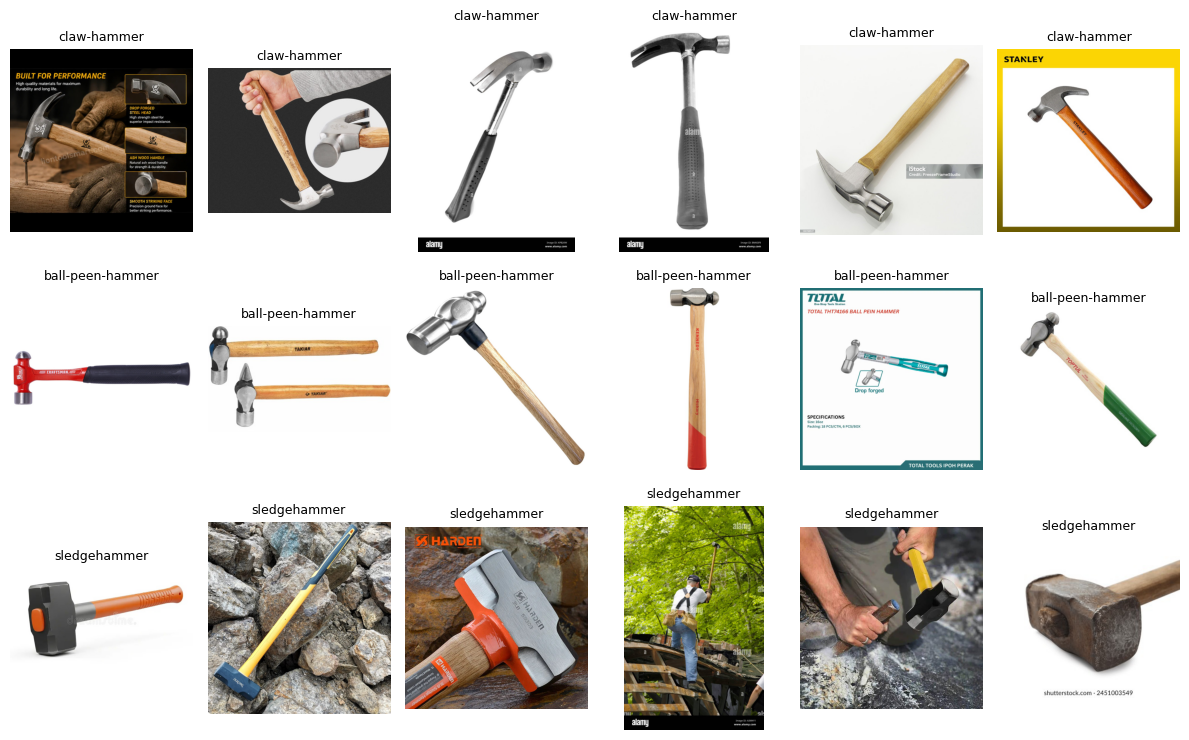

In [9]:
fig, axes = plt.subplots(
    len(CLASS_QUERIES),
    6,
    figsize=(12, 2.5 * len(CLASS_QUERIES)),
    squeeze=False
)

for row_number, label in enumerate(CLASS_QUERIES):
    candidates = manifest[
        manifest['label'].eq(label)
        & as_bool(manifest['readable'])
    ]
    candidates = candidates[
        candidates['filename'].map(
            lambda filename: (RAW / label / filename).is_file()
        )
    ]
    sample = candidates.sample(
        n=min(6, len(candidates)),
        random_state=SEED
    )

    for axis in axes[row_number]:
        axis.axis('off')

    for axis, row in zip(
        axes[row_number], sample.itertuples(index=False)
    ):
        with Image.open(RAW / label / row.filename) as image:
            axis.imshow(image.convert('RGB'))
        axis.set_title(label, fontsize=9)

plt.tight_layout()
plt.show()

**Outcome:** The preview displays **18 images six per class**. The samples include different handle materials, viewing angles, product photographs, and tools in use. Some images contain advertising text, watermarks, borders, or multiple tools. The outdoor scene in the sledgehammer row requires closer review because the tool is difficult to identify at this scale.

**Interpretation:** The samples show useful visual variation alongside potential distractions. Branding, text, and backgrounds could influence classification instead of hammer-head geometry. Notebook 2 must review the full dataset for ambiguous subjects, incorrect labels, duplicates, and unsuitable promotional images, then verify at least **200 usable images per class**.


## 6. Turning the Records into a Manifest

I saved the accumulated acquisition records to `data/P2_manifest.csv`, with one row per acquired image. The manifest contains **1,200 records** across the three hammer classes.

Each record includes the required fields: `filename`, `label`, `source_url`, `query`, and a boolean `readable` value established by the integrity check in Section 4.1.

**Search results change over time**, so repeating the same queries may produce a different dataset. The manifest preserves acquisition provenance and file references; reproducing the exact dataset also requires retaining the corresponding local images.

Notebook 2 adds or updates a `kept` column to record cleaning decisions while preserving the original acquisition fields and any existing cleaning information.

**Interpretation:** The manifest documents the acquired dataset. After cleaning, the `kept` column identifies images retained for subsequent preparation and modeling.

In [10]:
# Keep any existing cleaning columns; N2 adds/updates kept without dropping provenance.
MANIFEST_PATH.parent.mkdir(exist_ok=True)
manifest.to_csv(MANIFEST_PATH, index=False)
save_json(ROOT / 'data/P2_class_plan.json', {
    'class_queries': CLASS_QUERIES, 'predicted_confusion_pair': config['confusion_prediction'],
    'reason': config['confusion_reason'], 'config_sha256': digest(ROOT / 'config/project.json')})
display(manifest[['filename', 'label', 'query', 'readable']].head())
print('Manifest rows:', len(manifest))

,filename,label,query,readable
0,b5a9a596f05e_claw-hammer_0000.jpg,claw-hammer,claw hammer tool photograph,True
1,b5a9a596f05e_claw-hammer_0001.jpg,claw-hammer,claw hammer wooden handle,True
2,b5a9a596f05e_claw-hammer_0002.jpg,claw-hammer,claw hammer tool photograph,True
3,b5a9a596f05e_claw-hammer_0003.jpg,claw-hammer,claw hammer wooden handle,True
4,b5a9a596f05e_claw-hammer_0004.jpg,claw-hammer,claw hammer tool photograph,True


Manifest rows: 1200


#### Outcome
The exported manifest contains 1,200 acquisition records. `data/P2_manifest.csv` retains each source record, boolean `readable`, and any existing cleaning columns. The preview shows five claw-hammer records with their filenames, search queries, and readable=True flags. The full manifest also retains source_url, which is not included in this preview.
#### Interpretation
The uploaded run reports 1,200 manifest rows and zero unreadable/missing files. These five images passed the readability check. The manifest preserves acquisition provenance, while Notebook 2 will record label review and duplicate-removal decisions in the kept column. The 1,200 records represent acquired images, not the final cleaned training dataset.

**Next:** `P2_Images-2_Preprocessing_<TeamName>.ipynb` turns this folder of search results into
an actual dataset.